## 1. Environment setup

Run this section first in a fresh runtime.

In [ ]:
from pathlib import Path
import os
import random
import zipfile
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_ROOT = Path("/content/chestscan_data")
DATASET_DIR = DATA_ROOT / "chest_xray"
ZIP_PATH = Path("/content/chest-xray-pneumonia.zip")

print("Working directory:", Path.cwd())
print("Python:", sys.version.split()[0])

Working directory: /content
Python: 3.13.16


In [ ]:
# TensorFlow is used later for model work; this is only an environment check.
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPUs: []


## 2. Recover the dataset

In [ ]:
if not DATASET_DIR.exists():
    try:
        from google.colab import userdata
        kaggle_token = userdata.get("KAGGLE_API_TOKEN")
    except Exception as exc:
        raise RuntimeError(
            "KAGGLE_API_TOKEN was not available. Add it in Colab Secrets, "
            "enable notebook access, then rerun this cell."
        ) from exc

    if not kaggle_token:
        raise RuntimeError(
            "KAGGLE_API_TOKEN is empty. Add a valid replacement token in Colab Secrets."
        )

    # Keep the token out of notebook source and command output.
    os.environ["KAGGLE_API_TOKEN"] = kaggle_token

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "kaggle"],
        check=True
    )

    # Check authentication separately so the actual error is visible.
    auth_check = subprocess.run(
        ["kaggle", "datasets", "list", "-s", "chest xray pneumonia"],
        text=True,
        capture_output=True
    )
    print("Kaggle authentication/search exit code:", auth_check.returncode)
    if auth_check.stdout:
        print(auth_check.stdout[:5000])
    if auth_check.stderr:
        print("Kaggle stderr:")
        print(auth_check.stderr[:5000])

    if auth_check.returncode != 0:
        raise RuntimeError(
            "Kaggle authentication or API access failed. Read the output above; "
            "do not continue to dataset download yet."
        )

    if not ZIP_PATH.exists():
        download = subprocess.run(
            [
                "kaggle", "datasets", "download",
                "-d", "paultimothymooney/chest-xray-pneumonia",
                "-p", "/content"
            ],
            text=True,
            capture_output=True
        )
        print("Kaggle download exit code:", download.returncode)
        if download.stdout:
            print(download.stdout[:5000])
        if download.stderr:
            print("Kaggle stderr:")
            print(download.stderr[:5000])
        if download.returncode != 0:
            raise RuntimeError(
                "Dataset download failed. Share the error output above, "
                "with all credentials/tokens redacted."
            )

    DATA_ROOT.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        archive.extractall(DATA_ROOT)

if not DATASET_DIR.exists():
    raise FileNotFoundError(
        f"Expected dataset directory was not found: {DATASET_DIR}. "
        "Check the archive's extracted folder structure."
    )

print("Dataset directory:", DATASET_DIR)
print("Dataset exists:", DATASET_DIR.exists())
print("Splits found:", sorted(p.name for p in DATASET_DIR.iterdir() if p.is_dir()))

Kaggle authentication/search exit code: 0
ref                                                             title                                                      size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------  --------------------------------------------------  -----------  --------------------------  -------------  ---------  ---------------  
divyam6969/chest-xray-pneumonia-dataset                         Chest XRAY - Pneumonia Dataset                       1151535496  2024-01-17 12:19:16.570000           1546         30  0.6875           
kostasdiamantaras/chest-xrays-bacterial-viral-pneumonia-normal  Chest Xrays: bacterial / viral pneumonia / normal    1222999548  2020-10-27 16:51:15.783000           6304         22  0.7058824        
amanullahasraf/covid19-pneumonia-normal-chest-xray-pa-dataset   COVID19_Pneumonia_Normal_Chest_Xray_PA_Dataset       2053474983  2020-07-13 05:54:22.48300

## 3. Verify original split counts

This is a fresh count from the files present in this runtime. Do not assume the previously observed total until this cell confirms it.

In [ ]:
EXPECTED_SPLITS = ["train", "val", "test"]
CLASSES = ["NORMAL", "PNEUMONIA"]
IMAGE_EXTENSIONS = {".jpeg", ".jpg", ".png"}

count_rows = []
for split in EXPECTED_SPLITS:
    for label in CLASSES:
        folder = DATASET_DIR / split / label
        if not folder.is_dir():
            raise FileNotFoundError(f"Required class folder is missing: {folder}")
        count = sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
        )
        count_rows.append({"split_original": split, "label": label, "count": count})

counts_df = pd.DataFrame(count_rows)
display(counts_df.pivot(index="split_original", columns="label", values="count"))
print("Total images counted:", int(counts_df["count"].sum()))

label,NORMAL,PNEUMONIA
split_original,,
test,234,390
train,1341,3875
val,8,8


Total images counted: 5856


## 4. EDA — visualize training samples

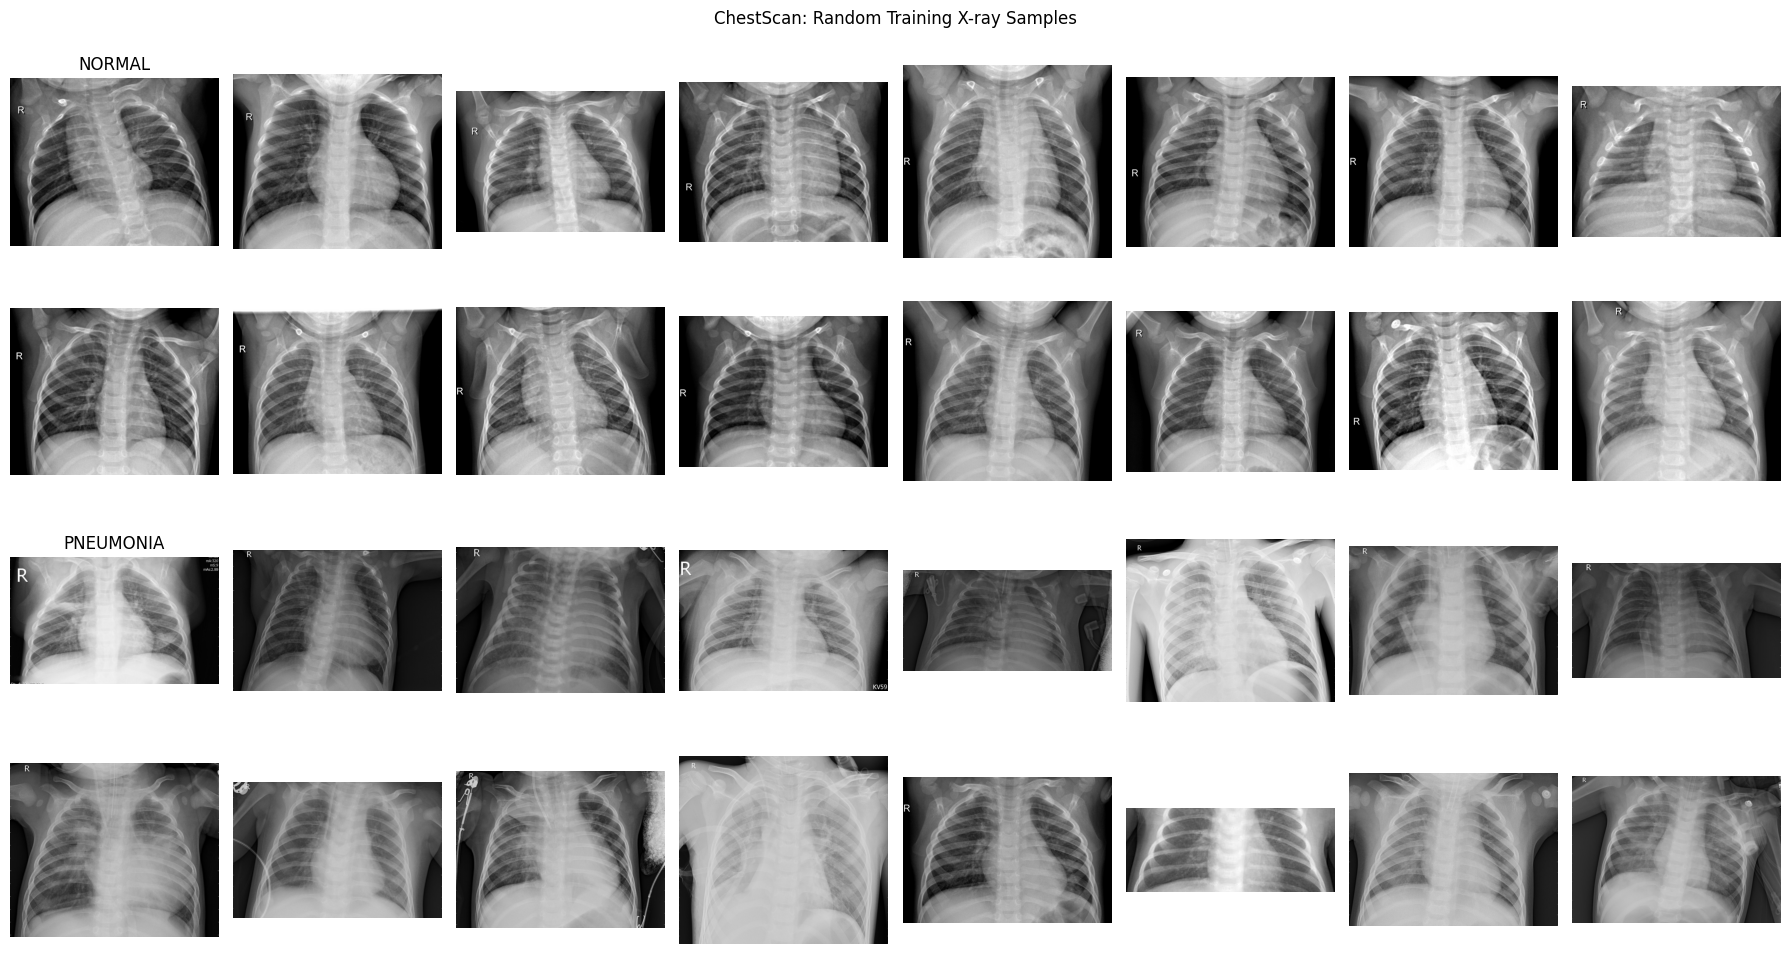

In [ ]:
fig, axes = plt.subplots(4, 8, figsize=(18, 10))
for row, label in enumerate(CLASSES):
    folder = DATASET_DIR / "train" / label
    image_paths = sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    selected = random.sample(image_paths, min(16, len(image_paths)))

    for i, image_path in enumerate(selected):
        ax = axes[row * 2 + i // 8, i % 8]
        with Image.open(image_path) as img:
            ax.imshow(img.convert("L"), cmap="gray")
        ax.set_title(label if i == 0 else "")
        ax.axis("off")

plt.suptitle("ChestScan: Random Training X-ray Samples")
plt.tight_layout()
plt.show()

## 5. EDA — inspect image dimensions and modes

Inspect a reproducible sample of up to 500 images per training class.

In [ ]:
records = []
for label in CLASSES:
    folder = DATASET_DIR / "train" / label
    image_paths = sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    selected = image_paths[:500]

    for path in selected:
        try:
            with Image.open(path) as img:
                records.append({
                    "label": label,
                    "filename": path.name,
                    "width": img.width,
                    "height": img.height,
                    "mode": img.mode,
                })
        except Exception as exc:
            print("Could not read:", path.name, "|", str(exc))

df_images = pd.DataFrame(records)
print("Images inspected:", len(df_images))
print("\nImage modes:")
display(df_images["mode"].value_counts().rename_axis("mode").to_frame("count"))
print("\nMost common dimensions:")
display(
    df_images.groupby(["width", "height"]).size()
    .sort_values(ascending=False).head(10).to_frame("count")
)

Images inspected: 1000

Image modes:


,count
mode,
L,968
RGB,32



Most common dimensions:


,,count
width,height,
1080,752,3
1016,664,2
1088,712,2
1168,608,2
912,480,2
1136,688,2
1064,632,2
1467,1044,2
992,592,2


## 6. EDA — brightness distributions

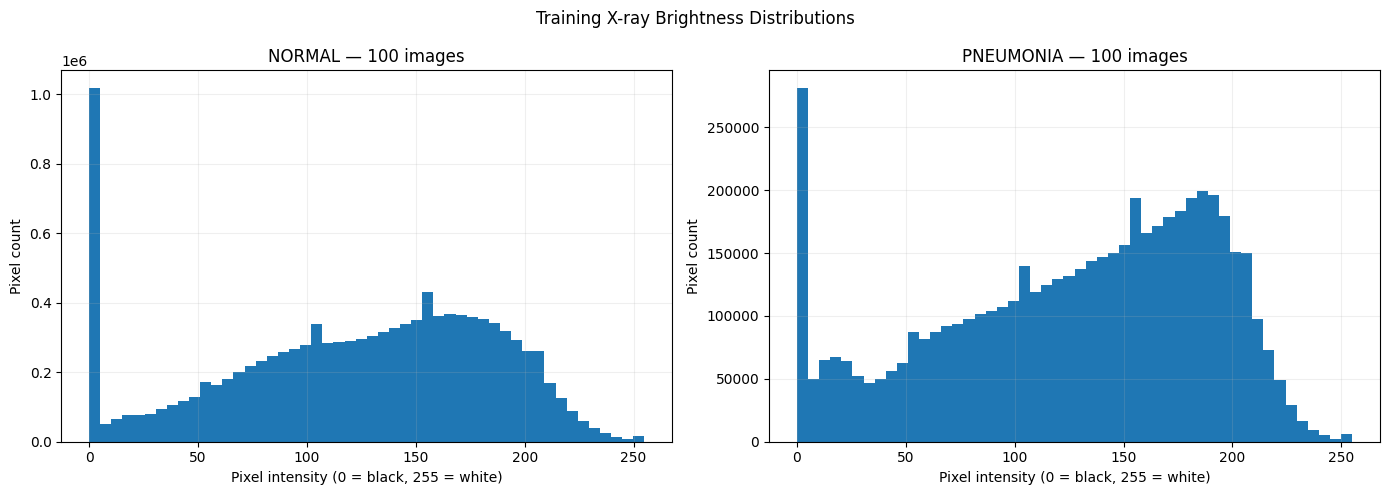

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, label in zip(axes, CLASSES):
    folder = DATASET_DIR / "train" / label
    image_paths = sorted(
        p for p in folder.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )
    selected = random.sample(image_paths, min(100, len(image_paths)))
    pixel_samples = []

    for path in selected:
        with Image.open(path) as img:
            pixels = np.asarray(img.convert("L"), dtype=np.uint8)
        pixel_samples.append(pixels.ravel()[::20])

    if pixel_samples:
        all_pixels = np.concatenate(pixel_samples)
        ax.hist(all_pixels, bins=50, range=(0, 255))
    ax.set_title(f"{label} — {len(selected)} images")
    ax.set_xlabel("Pixel intensity (0 = black, 255 = white)")
    ax.set_ylabel("Pixel count")
    ax.grid(alpha=0.2)

plt.suptitle("Training X-ray Brightness Distributions")
plt.tight_layout()
plt.show()

## 7. EDA — image integrity check

In [ ]:
total_files = 0
unreadable = []
unexpected = []

for split in EXPECTED_SPLITS:
    for label in CLASSES:
        folder = DATASET_DIR / split / label
        for path in folder.iterdir():
            if not path.is_file():
                continue
            total_files += 1

            if path.suffix.lower() not in IMAGE_EXTENSIONS:
                unexpected.append(str(path))
                continue

            try:
                with Image.open(path) as img:
                    img.verify()
            except Exception as exc:
                unreadable.append((str(path), str(exc)))

print("Total files across class folders:", total_files)
print("Unexpected file extensions:", len(unexpected))
print("Unreadable images:", len(unreadable))

if unexpected:
    print("Examples of unexpected files:", unexpected[:10])
if unreadable:
    print("Examples of unreadable images:", unreadable[:10])

Total files across class folders: 5856
Unexpected file extensions: 0
Unreadable images: 0


## 8. Build image metadata and extract patient IDs

Filenames in this dataset often contain identifiers such as `person123_bacteria_456.jpeg` or `person123_virus_456.jpeg`. The patient ID is the leading `person...` component. The parser below leaves IDs missing when a filename does not match the expected pattern; review those rows rather than guessing.

In [24]:
import re

metadata_records = []

for split in EXPECTED_SPLITS:
    for label in CLASSES:
        folder = DATASET_DIR / split / label

        for path in sorted(folder.iterdir()):
            if not path.is_file() or path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue

            if label == "PNEUMONIA":
                match = re.match(
                    r"^(person\d+)_",
                    path.name,
                    flags=re.IGNORECASE
                )
            else:
                match = re.match(
                    r"^((?:NORMAL2?-)?IM-\d+)-",
                    path.name,
                    flags=re.IGNORECASE
                )

            metadata_records.append({
                "path": str(path),
                "filename": path.name,
                "label": label,
                "patient_id": match.group(1).lower() if match else None,
                "split_original": split,
            })

metadata_df = pd.DataFrame(metadata_records)

print("Metadata rows:", len(metadata_df))
print("Missing patient IDs:", int(metadata_df["patient_id"].isna().sum()))
print("Unique patients:", int(metadata_df["patient_id"].nunique(dropna=True)))

display(metadata_df.head())

Metadata rows: 5856
Missing patient IDs: 0
Unique patients: 3118


,path,filename,label,patient_id,split_original
0,/content/chestscan_data/chest_xray/train/NORMA...,IM-0115-0001.jpeg,NORMAL,im-0115,train
1,/content/chestscan_data/chest_xray/train/NORMA...,IM-0117-0001.jpeg,NORMAL,im-0117,train
2,/content/chestscan_data/chest_xray/train/NORMA...,IM-0119-0001.jpeg,NORMAL,im-0119,train
3,/content/chestscan_data/chest_xray/train/NORMA...,IM-0122-0001.jpeg,NORMAL,im-0122,train
4,/content/chestscan_data/chest_xray/train/NORMA...,IM-0125-0001.jpeg,NORMAL,im-0125,train


## 9. Inspect repeated images per patient and audit split overlap

A zero-overlap result is still a finding to record. Do not create a new split or train a model in this notebook section yet.

In [28]:
known_ids = metadata_df.dropna(subset=["patient_id"])

images_per_patient = (
    known_ids.groupby("patient_id")
    .size()
    .sort_values(ascending=False)
    .rename("image_count")
    .reset_index()
)

print("Patients with more than one image:",
      int((images_per_patient["image_count"] > 1).sum()))
display(images_per_patient.head(10))

patients_by_split = {
    split: set(known_ids.loc[known_ids["split_original"] == split, "patient_id"])
    for split in EXPECTED_SPLITS
}

overlap_rows = []
for i, split_a in enumerate(EXPECTED_SPLITS):
    for split_b in EXPECTED_SPLITS[i + 1:]:
        overlap = patients_by_split[split_a] & patients_by_split[split_b]
        overlap_rows.append({
            "split_a": split_a,
            "split_b": split_b,
            "overlapping_patient_count": len(overlap),
            "example_patient_ids": ", ".join(sorted(overlap)[:10]),
        })

overlap_df = pd.DataFrame(overlap_rows)
display(overlap_df)

Patients with more than one image: 1185


,patient_id,image_count
0,person23,31
1,person124,20
2,person441,18
3,person30,15
4,person1320,14
5,person348,13
6,person266,12
7,person281,12
8,person26,12
9,person1411,12


,split_a,split_b,overlapping_patient_count,example_patient_ids
0,train,val,0,
1,train,test,170,"person1, person10, person100, person101, perso..."
2,val,test,0,


## 10. Save audit artifacts

This writes a metadata CSV and a Markdown report under `/content` so they can be downloaded from the Colab file pane. Copy important artifacts to persistent storage before the runtime ends.

In [34]:
OUTPUT_DIR = Path("/content/chestscan_artifacts")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

metadata_csv = OUTPUT_DIR / "image_metadata.csv"
overlap_csv = OUTPUT_DIR / "original_split_patient_overlap.csv"
report_path = OUTPUT_DIR / "leakage_audit.md"

metadata_df.to_csv(metadata_csv, index=False)
overlap_df.to_csv(overlap_csv, index=False)

split_counts = (
    metadata_df.groupby(["split_original", "label"])
    .size().rename("count").reset_index()
)

report_lines = [
    "# ChestScan — Original Split Leakage Audit",
    "",
    "## Dataset verification",
    f"- Dataset directory: `{DATASET_DIR}`",
    f"- Total images: {len(metadata_df)}",
    f"- Unique parsed identifiers: {metadata_df['patient_id'].nunique()}",
    f"- Missing identifiers: {metadata_df['patient_id'].isna().sum()}",
    "",
    "## Original split counts",
    split_counts.to_markdown(index=False),
    "",
    "## Patient overlap between original splits",
    overlap_df.to_markdown(index=False),
    "",
    "## Train-test overlap findings",
    f"- Overlapping parsed identifiers: {len(train_test_overlap)}",
    f"- Test images belonging to overlapping identifiers: {len(test_overlap_images)}",
    f"- Test images belonging to test-only identifiers: {len(test_only_images)}",
    "- These identifiers are filename-derived proxies, not independently verified patient identities.",
    "- The original test set contains 624 images and remains unchanged.",
    "",
    "## Limitations and decisions",
    "- The original 16-image validation split will not be used for tuning.",
    "- The original split structure has potential patient-level leakage.",
    "- No new split or model training was performed during this audit.",
    "- ChestScan is a screening aid, not a diagnostic tool.",
]

report_path.write_text("\n".join(report_lines) + "\n", encoding="utf-8")

print("Saved:")
print(metadata_csv)
print(overlap_csv)
print(report_path)

Saved:
/content/chestscan_artifacts/image_metadata.csv
/content/chestscan_artifacts/original_split_patient_overlap.csv
/content/chestscan_artifacts/leakage_audit.md


# Audit artifacts

In [35]:
from pathlib import Path

report_path = Path("/content/chestscan_artifacts/leakage_audit.md")

report_text = f"""# ChestScan — Original Split Leakage Audit

## Dataset verification
- Total images: {len(metadata_df)}
- Unique parsed identifiers: {metadata_df["patient_id"].nunique()}
- Missing identifiers: {metadata_df["patient_id"].isna().sum()}

## Original split counts
{metadata_df.groupby(["split_original", "label"]).size().rename("count").to_frame().to_markdown()}

## Train-test overlap
- Overlapping parsed patient IDs: {len(train_test_overlap)}
- Test images belonging to overlapping IDs: {len(test_overlap_images)}
- Test images belonging to test-only IDs: {len(test_only_images)}
- Test-only NORMAL images: {int((test_only_images["label"] == "NORMAL").sum())}
- Test-only PNEUMONIA images: {int((test_only_images["label"] == "PNEUMONIA").sum())}

## Interpretation and limitations
- The original test set contains 624 images.
- 320 test images have parsed identifiers also present in training.
- 304 test images have identifiers absent from training.
- Restricting evaluation to test-only identifiers changes the test cohort and class balance.
- Filename-derived identifiers are proxies; patient identity has not been independently verified.
- Preserve the original dataset and test files. Do not silently remove overlapping images.
- ChestScan is a screening aid, not a diagnostic tool.
"""

report_path.write_text(report_text, encoding="utf-8")
print("Updated:", report_path)
print(report_text)

Updated: /content/chestscan_artifacts/leakage_audit.md
# ChestScan — Original Split Leakage Audit

## Dataset verification
- Total images: 5856
- Unique parsed identifiers: 3118
- Missing identifiers: 0

## Original split counts
|                        |   count |
|:-----------------------|--------:|
| ('test', 'NORMAL')     |     234 |
| ('test', 'PNEUMONIA')  |     390 |
| ('train', 'NORMAL')    |    1341 |
| ('train', 'PNEUMONIA') |    3875 |
| ('val', 'NORMAL')      |       8 |
| ('val', 'PNEUMONIA')   |       8 |

## Train-test overlap
- Overlapping parsed patient IDs: 170
- Test images belonging to overlapping IDs: 320
- Test images belonging to test-only IDs: 304
- Test-only NORMAL images: 234
- Test-only PNEUMONIA images: 70

## Interpretation and limitations
- The original test set contains 624 images.
- 320 test images have parsed identifiers also present in training.
- 304 test images have identifiers absent from training.
- Restricting evaluation to test-only identifiers c

In [36]:
from pathlib import Path
import zipfile

artifact_dir = Path("/content/chestscan_artifacts")
bundle_path = Path("/content/chestscan_day3_day4_bundle.zip")

required_files = [
    artifact_dir / "image_metadata.csv",
    artifact_dir / "original_split_patient_overlap.csv",
    artifact_dir / "leakage_audit.md",
]

for path in required_files:
    print(f"{path}: {'FOUND' if path.exists() else 'MISSING'}")

missing = [str(path) for path in required_files if not path.exists()]
if missing:
    raise FileNotFoundError(f"Missing required artifacts: {missing}")

with zipfile.ZipFile(bundle_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for path in required_files:
        archive.write(path, arcname=path.name)

print(f"Created: {bundle_path}")

/content/chestscan_artifacts/image_metadata.csv: FOUND
/content/chestscan_artifacts/original_split_patient_overlap.csv: FOUND
/content/chestscan_artifacts/leakage_audit.md: FOUND
Created: /content/chestscan_day3_day4_bundle.zip
